In [15]:
import os
import math
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colorbar as colorbar
import matplotlib.colors as mcolors

from anndata import AnnData
from typing import Tuple, Literal
from scipy.stats import pearsonr
from scipy.ndimage import gaussian_filter
from skimage.draw import polygon
from skimage.measure import find_contours
from matplotlib.lines import Line2D

In [6]:
def get_contour(adata, binsize = 8, target_labels = ["Tumor core", "Tumor surface"]):
     # yellow and red regions
    subset = adata[adata.obs["niches_3D"].isin(target_labels)].copy()
    # Create a grid (adjust bin size as needed)
    x = subset.obsm["spatial"][:, 0]
    y = subset.obsm["spatial"][:, 1]
    x_min = min(adata.obsm["spatial"][:, 0])
    y_min = min(adata.obsm["spatial"][:, 1])
    if min(x) < 0:
        x = x - x_min
    if min(y) < 0:
        y = y - y_min
    x_bins = (x / binsize).astype(int)
    y_bins = (y / binsize).astype(int)
    grid = np.zeros((y_bins.max()+1, x_bins.max()+1), dtype=int)
    grid[y_bins, x_bins] = 1
    grid = gaussian_filter(grid, sigma=0.1, radius=2, mode="mirror")  # smooth to get clearer contours
    contours = find_contours(grid, level=0.7, fully_connected="high")
    return contours, binsize, x_min, y_min

def plot_contour(contours, binsize, x_min, y_min, ax, min_len=30, linecolor="white", linewidth=2):
    for idx in np.where(np.array([len(c) for c in contours]) > min_len)[0]:
        contour = contours[idx]
        ax.plot(contour[:, 1]*binsize + x_min/binsize, contour[:, 0]*binsize + y_min, linewidth=linewidth, color=linecolor)  # swap x/y

def custom_cmap(cmap, vmin, vmax, center):
    cmap = plt.get_cmap(cmap)
    vrange = max(vmax - center, center - vmin)
    normlize = mcolors.Normalize(center - vrange, center + vrange)
    cmin, cmax = normlize([vmin, vmax])
    cc = np.linspace(cmin, cmax, 256)
    cmap2 = mcolors.ListedColormap(cmap(cc))
    return cmap2

def get_genesets(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype_signature: str,
    direction: str,
    threshold_pval: float,
    threshold_lfc: float,
    threshold_frac_shared_genes: float,
    min_size: int = None,
    max_size: int = None,
) -> Tuple[dict[str, list[str]], pd.DataFrame]:

    # construct signature gene set
    select = ((df_hcd_all.adj_p_value <= threshold_pval) & (df_hcd_all.celltype == celltype_signature))
    if direction == "upregulated":
        select = select & (df_hcd_all.log_fc >= threshold_lfc)
    elif direction == "downregulated":
        select = select & (df_hcd_all.log_fc <= threshold_lfc)
    elif direction == "both":
        select = select & (df_hcd_all.log_fc.abs() >= threshold_lfc)         
    
    df_hcd_ct = df_hcd_all.loc[select]
    gene_set_dict = {}
    gene_set_df = pd.DataFrame()
    for cytokine_i, cytokine in enumerate(df_hcd_ct.cytokine.unique()):
        gene_set = df_hcd_ct.loc[df_hcd_ct.cytokine == cytokine].gene.values
        gene_set_shared = np.intersect1d(gene_set, adata.var_names)
        frac_shared = len(gene_set_shared) / len(gene_set)
        
        row_idx = gene_set_df.shape[0]
        gene_set_df.loc[row_idx, "cytokine"] = cytokine
        gene_set_df.loc[row_idx, "num_genes_signature"] = len(gene_set)
        gene_set_df.loc[row_idx, "num_shared_genes_signature"] = len(gene_set_shared)
        gene_set_df.loc[row_idx, "frac_shared_genes_signature"] = frac_shared
        gene_set_df.loc[row_idx, "geneset"] = [[gene_set]]
        gene_set_df.loc[row_idx, "geneset_shared"] = [[gene_set_shared]]
        if (
            (len(gene_set_shared) > 0) 
            and (frac_shared >= threshold_frac_shared_genes) 
            and (len(gene_set_shared) >= min_size)
            and len(gene_set_shared) <= max_size
        ):
            gene_set_dict[cytokine] = gene_set_shared

    return gene_set_dict, gene_set_df

In [8]:
df_hcd_all = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/DEGs/DEGs_all_with_pbs_DE_count.csv", index_col=0)
questionable_genes = set(pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/01_overview/questionable_genes.csv")['gene'])
df_hcd_all = df_hcd_all.loc[
    (
        (df_hcd_all['pbs_well'] > 3) 
        & (~df_hcd_all['gene'].isin(questionable_genes))
        & (df_hcd_all['adj_p_value'] < 0.05)
    )
]

In [3]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/07_spatial/NSCLC_3D.h5ad")
adata = adata[adata.obs.niches_3D != "Excluded"]
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)

(np.float32(0.0), np.float32(1334.0))

In [13]:
niche_colors = {
    'Airways': '#332288',
    'Alveolar spaces': '#88CCEE',
    'DC islands': '#44AA99',
    'Desmoplastic stroma': '#117733',
    'Macrophage islands': '#999933',
    'Smooth muscle': '#DDCC77',
    'T cell aggregates': '#CC6677',
    'Tumor core': '#882255',
    'Tumor surface': '#AA4499',
    'Vascular stroma': '#DDDDDD',
}

adata.uns["niches_3D_colors"] = list(niche_colors.values())

In [412]:
list(adata.obs.celltypes.unique())

['Tumor cells',
 'Macrophages',
 'Cytotoxic T cells',
 'Fibroblasts',
 'Cycling immune cells',
 'Monocytes',
 'Vascular endothelium',
 'Regulatory T cells',
 'Mast cells',
 'Pericytes',
 'Respiratory epithelium',
 'B cells',
 'Lymphatic endothelial cells',
 'Smooth muscle cells',
 'Plasma cells',
 'Dendritic cells',
 'Basal epithelial cells',
 'Alveolar cells']

In [413]:
list(adata.obs.niches_3D.unique())

['Tumor core',
 'Tumor surface',
 'Vascular stroma',
 'T cell aggregates',
 'Smooth muscle structures',
 'Desmoplastic stroma',
 'Macrophage islands',
 'Airways',
 'Alveolar spaces',
 'DC islands']

In [388]:
# cytokine = "GM-CSF"
cytokine = "IL-3"
celltype_adata = "Monocytes"
celltype_signature = "CD14_Mono"
section = "section_28"
colors = dict(zip(sorted(adata.obs.niches_3D.unique()), adata.uns['niches_3D_colors']))

In [419]:
# cytokine = "GM-CSF"
# cytokine = "IFN-beta"
cytokine = "IL-15"
celltype_adata = "Cytotoxic T cells"
celltype_signature = "CD8_T_cell"
section = "section_28"
colors = dict(zip(sorted(adata.obs.niches_3D.unique()), adata.uns['niches_3D_colors']))

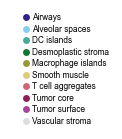

In [420]:
legend_elements = [
    Line2D([0], [0], marker='o', color='white', markerfacecolor=color, markersize=6, label=label)
    for label, color in niche_colors.items()
]
fig, ax = plt.subplots(figsize=(1.3, 1.3))
ax.axis('off')
legend = ax.legend(
    handles=legend_elements,
    loc='center left',
    frameon=False,
    prop={'size': 6, 'family': 'Arial'},
    handletextpad=-0.2,
    labelspacing=0.3
)
plt.savefig(f"./final_figures/niche_color_legend_round.svg", bbox_inches="tight", pad_inches=0, dpi=500, transparent=True)
plt.show()

In [421]:
cdata = adata[adata.obs.section == section].copy()

In [422]:
bdata  = cdata[cdata.obs.celltypes == celltype_adata].copy()

genesets, _ = get_genesets(
    adata, 
    df_hcd_all, 
    celltype_signature, 
    direction="upregulated", 
    threshold_pval=0.05, 
    threshold_lfc=1,
    threshold_frac_shared_genes=0.1,
    min_size=0,
    max_size=10000,
)

signature = genesets[cytokine]
signature = np.intersect1d(signature, bdata.var_names)

In [423]:
### mean signature expression ###
bdata.obs.loc[:, f"{cytokine}_mean_expression"] = np.exp(np.nanmean(np.asarray(bdata[:, signature].X.todense()), axis=1) - 1)
### (mean signature expression - dataset mean) / std ###
# dataset_means = bdata[:, signature].X.mean(axis=0)
dataset_means = bdata[:, signature].X.mean(axis=0)
dataset_stds = 1 #bdata[:, signature].X.todense().std(axis=0)
fcs = (np.asarray(bdata[:, signature].X - dataset_means)) / dataset_stds
print(fcs.shape, len(signature))
bdata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"] = np.nanmean(fcs, axis=1)

vmin = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].min()
vmax = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].quantile(0.98)
center = 0

(5708, 75) 75


In [ ]:
ddata.obs.loc[:, f"upper_quanile"] = ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"] > threshold

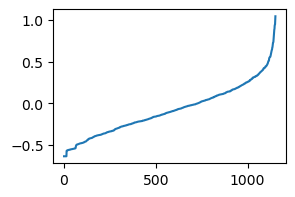

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


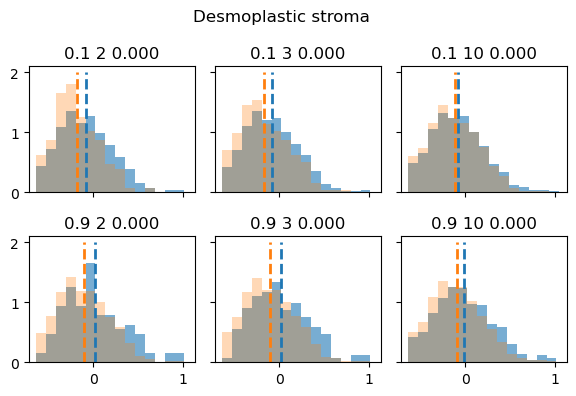

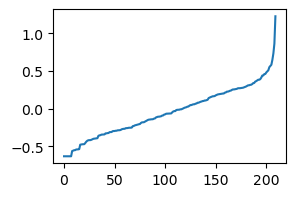

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


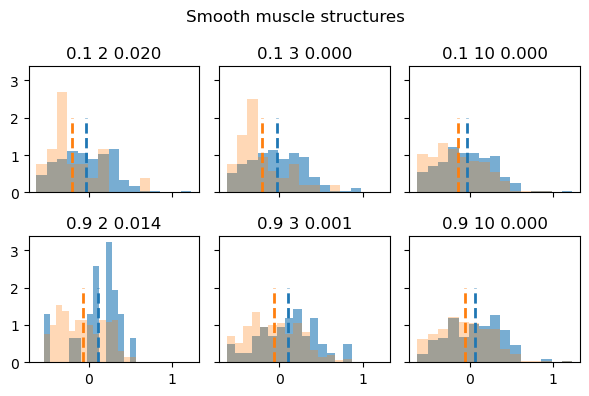

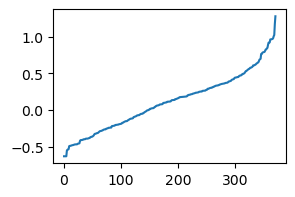

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


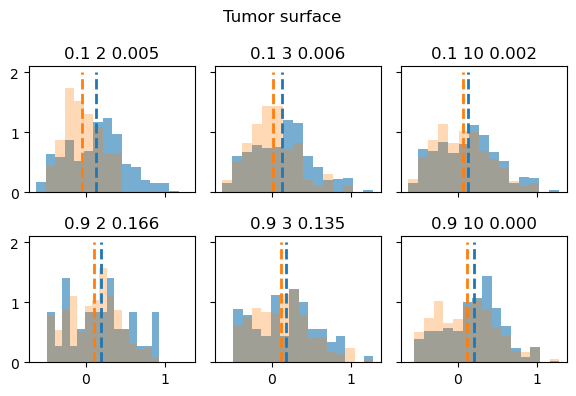

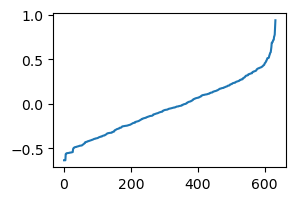

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


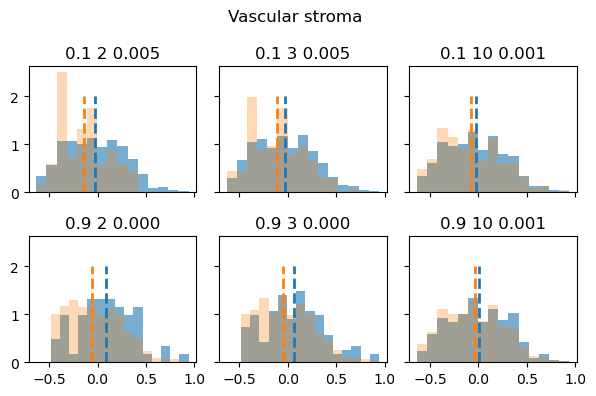

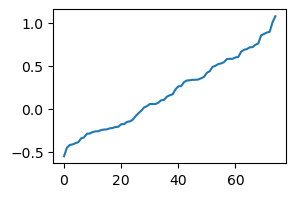

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


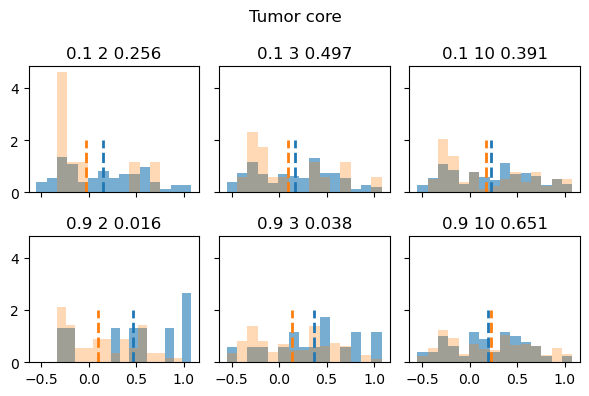

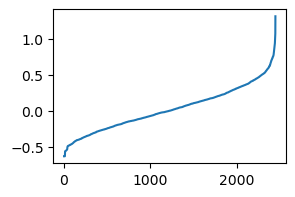

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


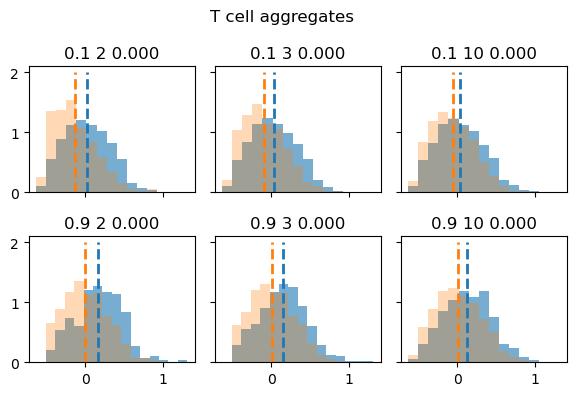

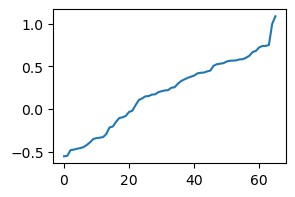

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


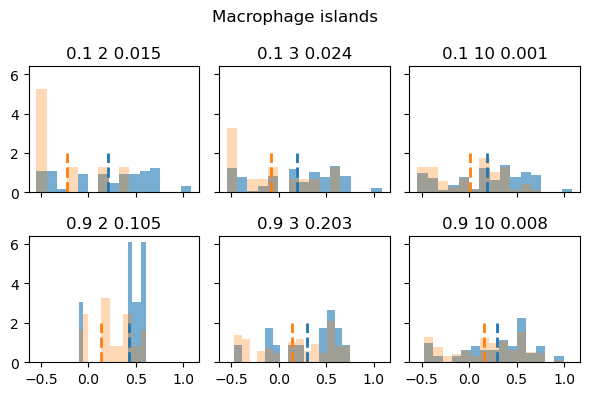

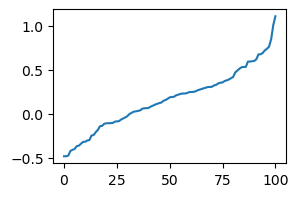

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


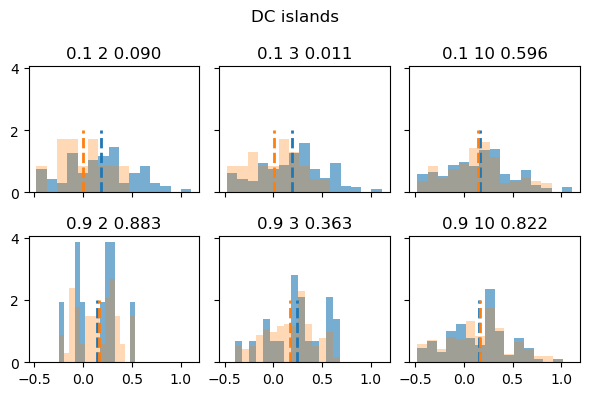

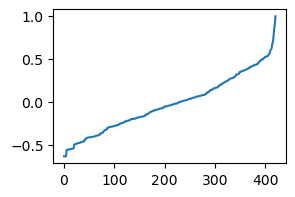

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


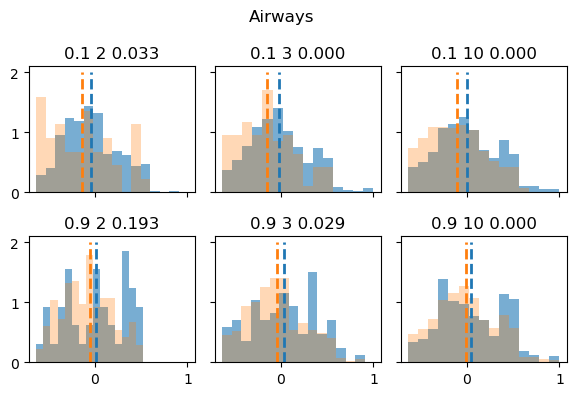

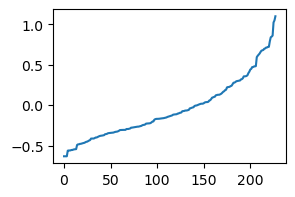

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


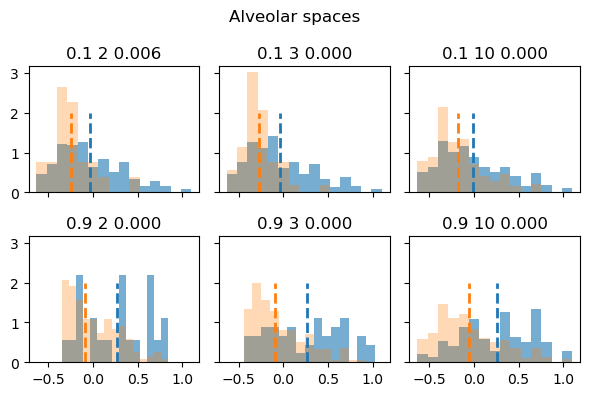

In [424]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
from scipy.stats import ttest_ind

# all_quantiles = [0.1, 0.5, 0.7, 0.8, 0.9, 0.95]
all_quantiles = [0.1, 0.9]
# all_ks = [2, 3, 4, 5, 10]
all_ks = [2, 3, 10]

for niche in bdata.obs.niches_3D.unique():
    
    ddata = bdata[bdata.obs.niches_3D == niche]
    ddata = ddata[~ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].isna()]

    fig, ax = plt.subplots(1,1,figsize=(3, 2))
    plt.plot(sorted(ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values))
    plt.show()
    
    fig, axs = plt.subplots(len(all_quantiles), len(all_ks), figsize=(2*len(all_ks), 2*len(all_quantiles)), sharex=True, sharey=True)
    for q_i, quantile in enumerate(all_quantiles):
        threshold = ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].quantile(quantile)
        ddata.obs.loc[:, f"upper_quanile"] = ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"] >= threshold
        # display(bdata.obs.loc[(bdata.obs.upper_quanile == True)].reset_index().groupby("niches_3D").index.nunique().sort_values(ascending=False))
        for k_i, k in enumerate(all_ks):
            ax = axs[q_i, k_i]
            X = ddata.obsm["spatial"][:, :2]
            X_high = ddata[(ddata.obs.upper_quanile == True)].obsm["spatial"][:, :2]
            X_low = ddata[(ddata.obs.upper_quanile == False)].obsm["spatial"][:, :2]
            if X_high.shape[0] == 0:
                continue
            nbrs = NearestNeighbors(n_neighbors=min(k, X.shape[0]), algorithm='auto').fit(X)
            distances_high, indices_high = nbrs.kneighbors(X_high)
            distances_low, indices_low = nbrs.kneighbors(X_low)
            scores_high, scores_low = [], []
            for i in range(indices_high.shape[0]):
                scores_high.extend(ddata.obs.iloc[indices_high[i, 1:]][f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values)
            for i in range(indices_low.shape[0]):
                scores_low.extend(ddata.obs.iloc[indices_low[i, 1:]][f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values)
            _, bins, _ = ax.hist(scores_high, density=True, alpha=0.6, bins=15)
            ax.hist(scores_low, bins=bins, alpha = 0.3, density=True)
            ax.plot([np.mean(scores_high), np.mean(scores_high)], [0, 2], "C0--", lw=2)
            ax.plot([np.mean(scores_low), np.mean(scores_low)], [0, 2], "C1--", lw=2)
            pval = ttest_ind(scores_high, scores_low).pvalue
            ax.set_title(f"{quantile} {k} {pval:5.3f}")
    plt.suptitle(niche)
    plt.tight_layout()
    plt.show()

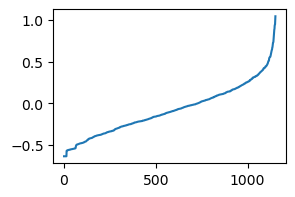

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


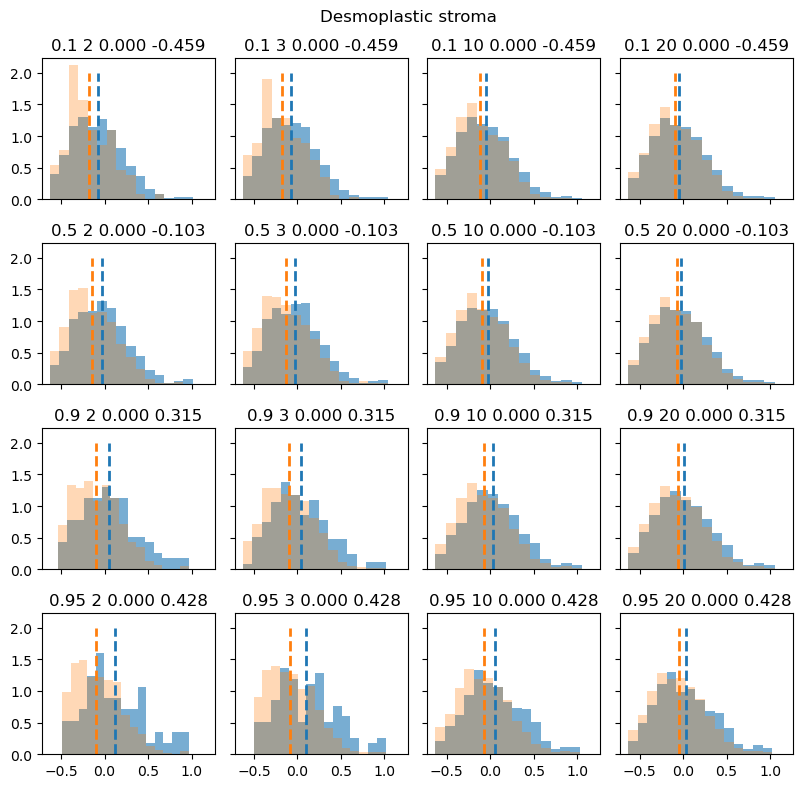

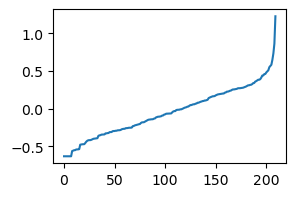

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


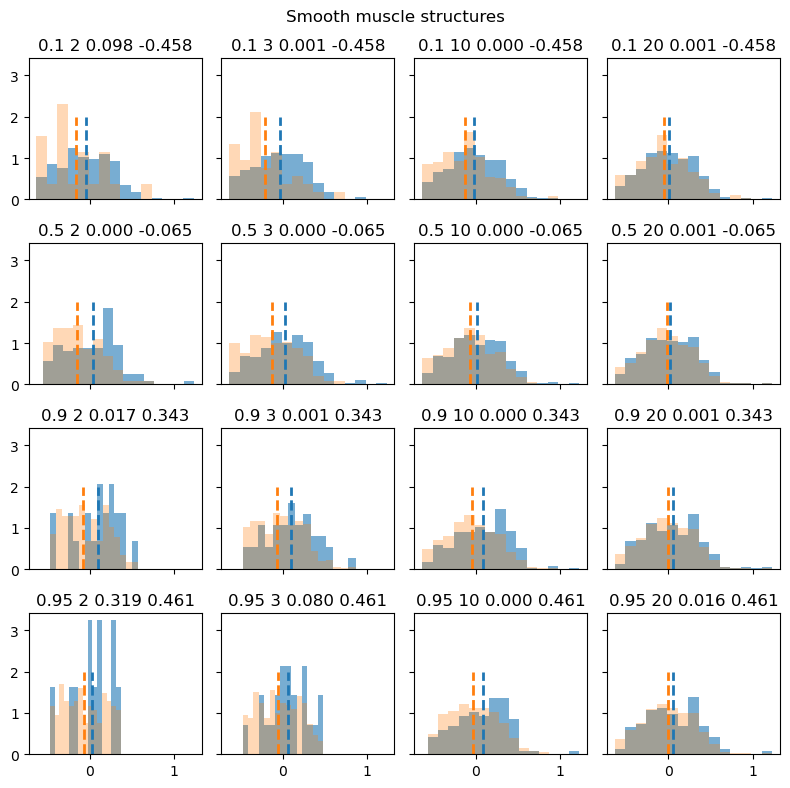

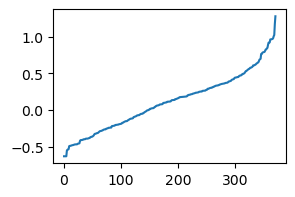

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


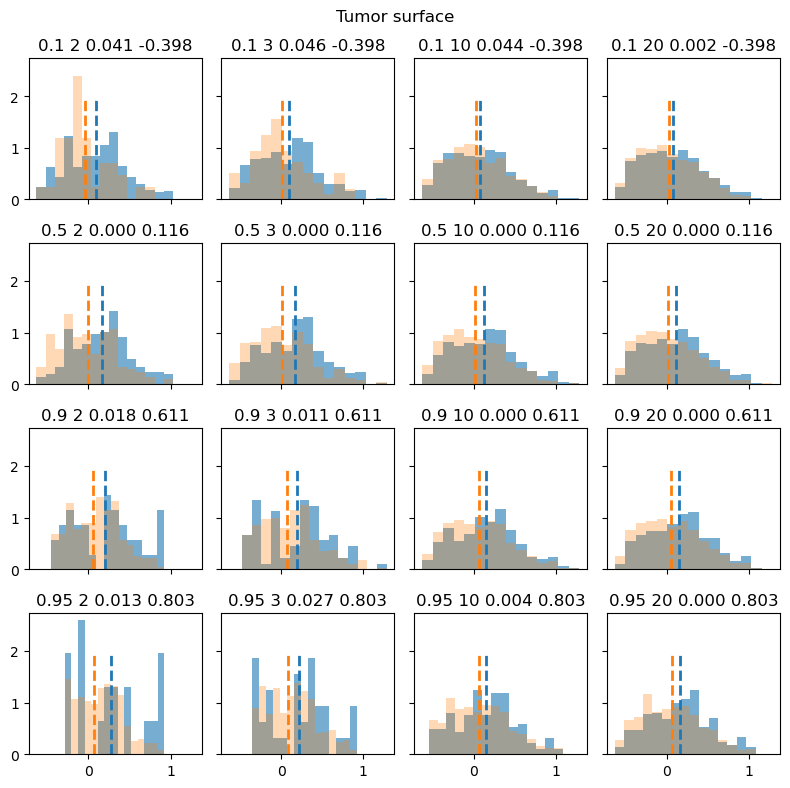

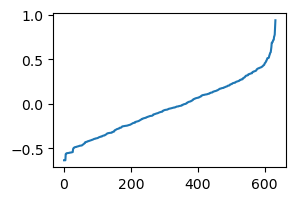

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


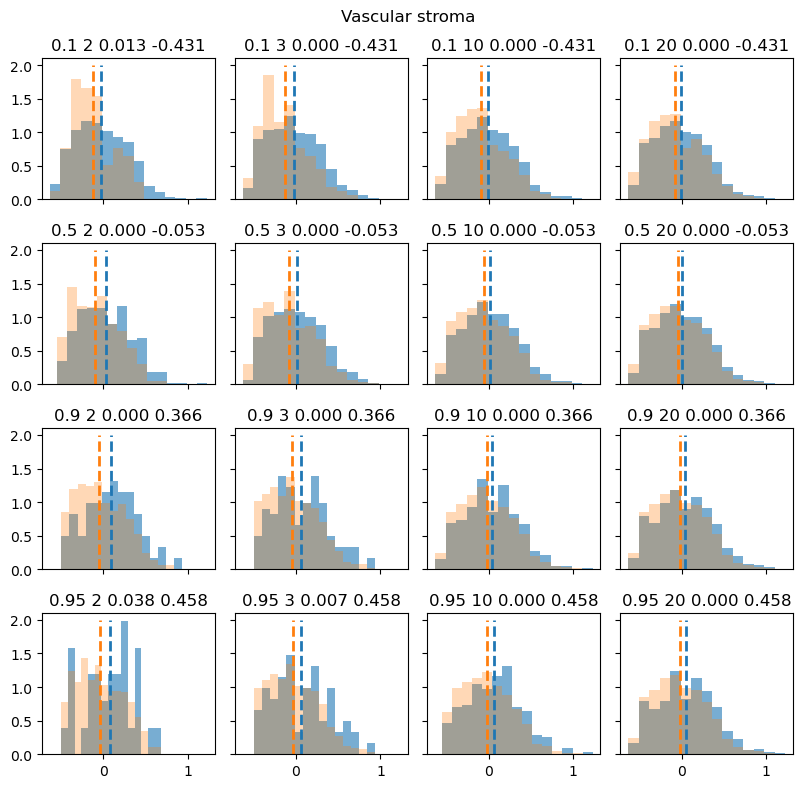

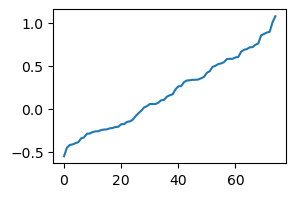

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


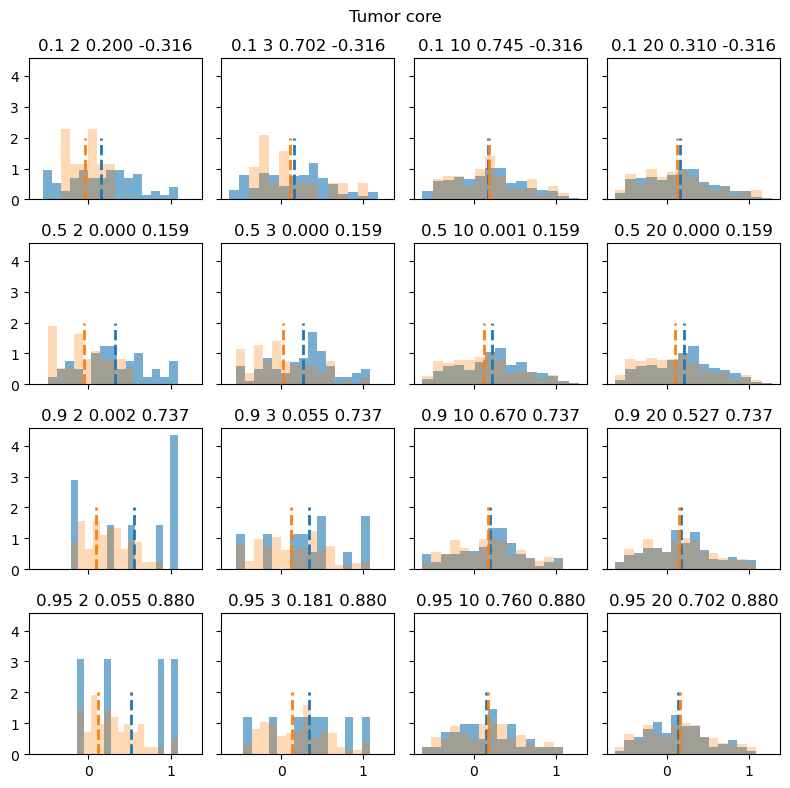

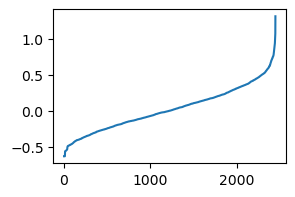

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


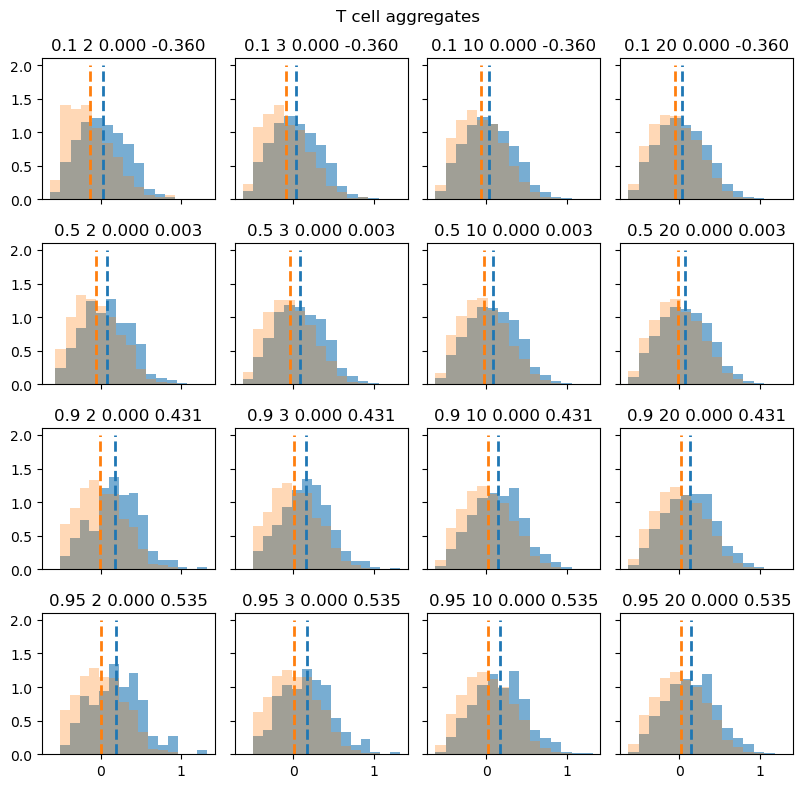

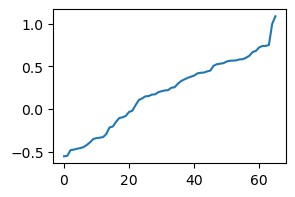

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


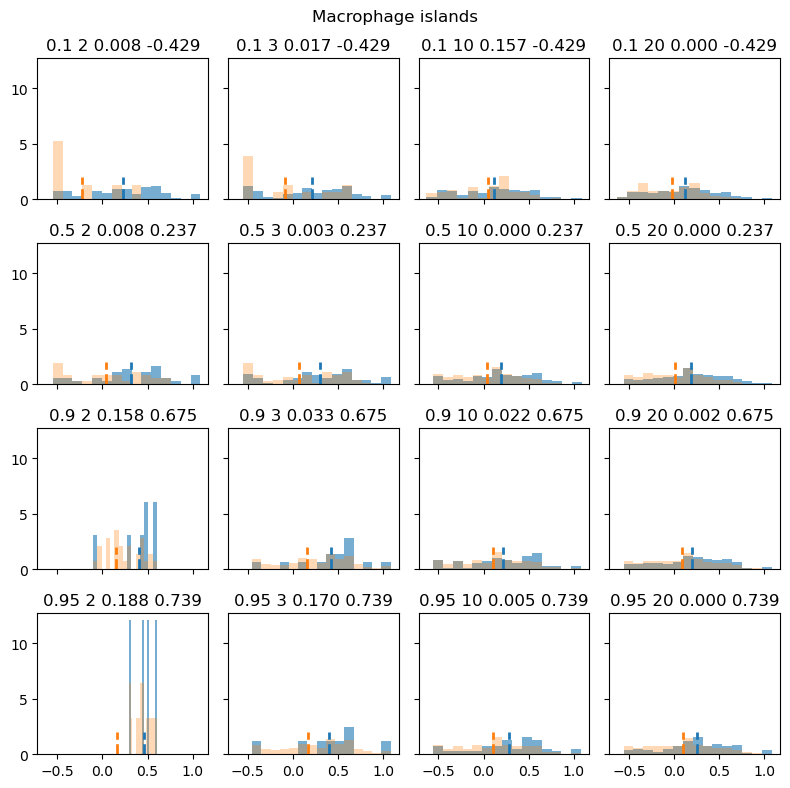

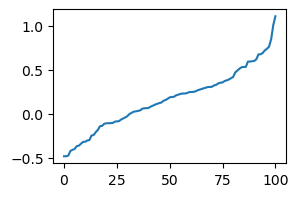

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


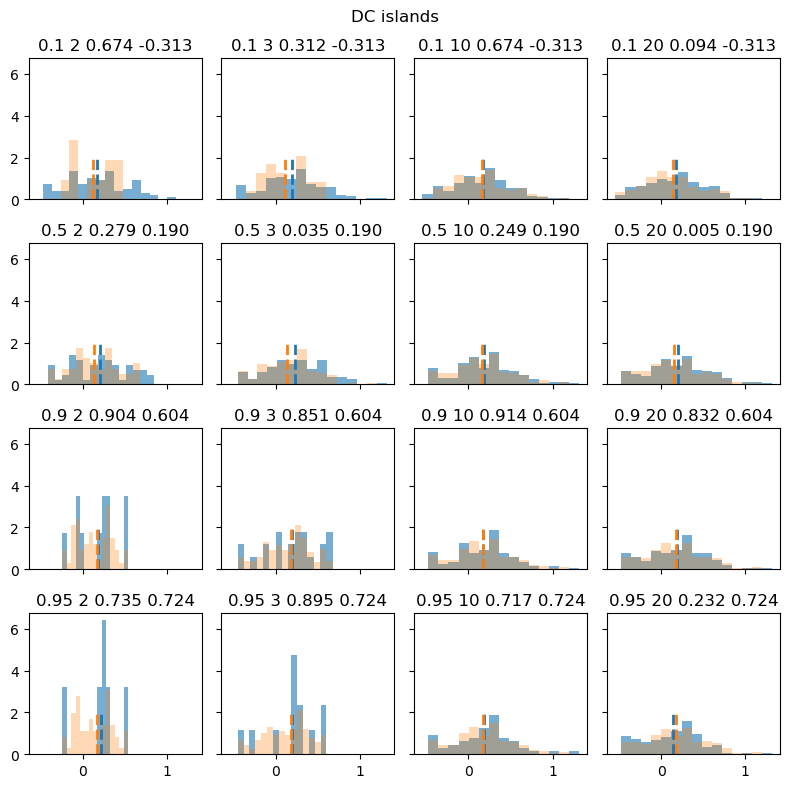

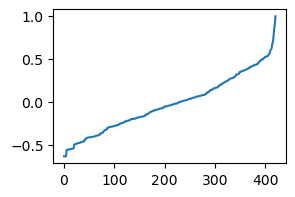

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


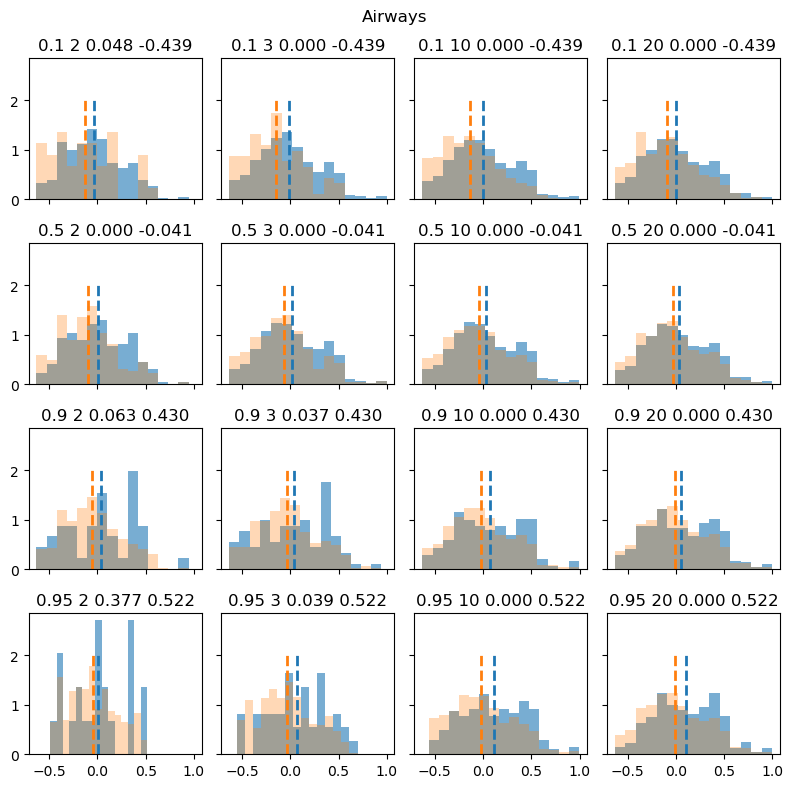

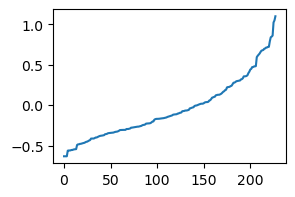

/Users/soeren.becker/micromamba/envs/env_gsea2/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value


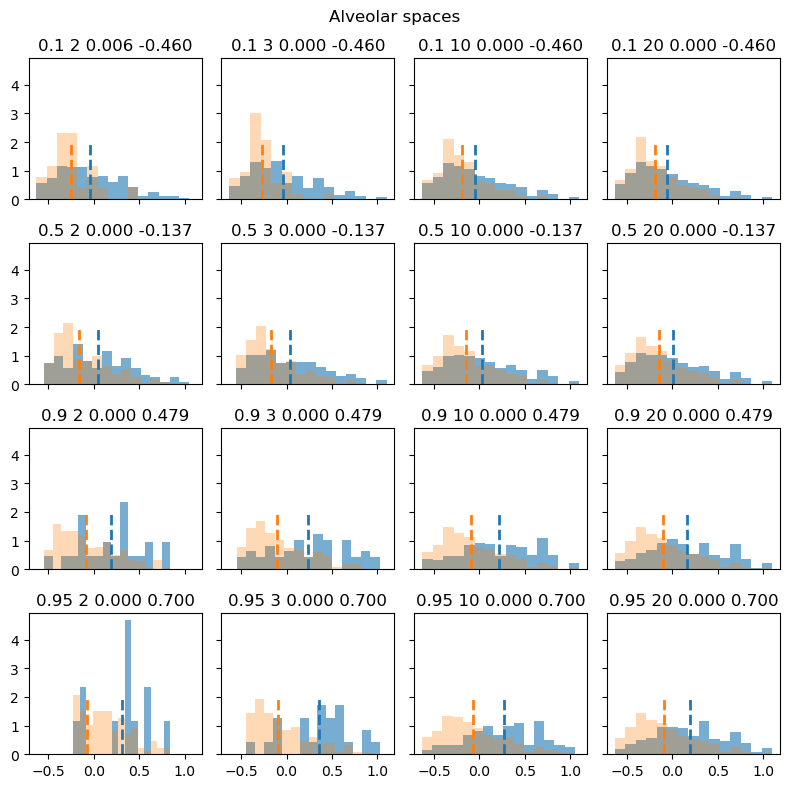

In [429]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
from scipy.stats import ttest_ind

# all_quantiles = [0.1, 0.5, 0.7, 0.8, 0.9, 0.95]
all_quantiles = [0.1, 0.5, 0.9, 0.95]
# all_ks = [2, 3, 4, 5, 10]
all_ks = [2, 3, 10, 20]

for niche in bdata.obs.niches_3D.unique():
    
    ddata = bdata[bdata.obs.niches_3D == niche]
    ddata = ddata[~ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].isna()]

    fig, ax = plt.subplots(1,1,figsize=(3, 2))
    plt.plot(sorted(ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values))
    plt.show()
    
    fig, axs = plt.subplots(len(all_quantiles), len(all_ks), figsize=(2*len(all_ks), 2*len(all_quantiles)), sharex=True, sharey=True)
    for q_i, quantile in enumerate(all_quantiles):
        threshold = ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"].quantile(quantile)
        ddata.obs.loc[:, f"upper_quanile"] = ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"] >= threshold
        # display(bdata.obs.loc[(bdata.obs.upper_quanile == True)].reset_index().groupby("niches_3D").index.nunique().sort_values(ascending=False))
        for k_i, k in enumerate(all_ks):
            ax = axs[q_i, k_i]
            X = bdata.obsm["spatial"][:, :2]
            X_high = ddata[(ddata.obs.upper_quanile == True)].obsm["spatial"][:, :2]
            X_low = ddata[(ddata.obs.upper_quanile == False)].obsm["spatial"][:, :2]
            if X_high.shape[0] == 0:
                continue
            if X_low.shape[0] == 0:
                continue
            nbrs = NearestNeighbors(n_neighbors=min(k, X.shape[0]), algorithm='auto').fit(X)
            distances_high, indices_high = nbrs.kneighbors(X_high)
            distances_low, indices_low = nbrs.kneighbors(X_low)
            scores_high, scores_low = [], []
            for i in range(indices_high.shape[0]):
                _indices_high = bdata.obs.iloc[indices_high[i, 1:]].index
                scores_high.extend(bdata.obs.loc[_indices_high][f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values)
            for i in range(indices_low.shape[0]):
                _indices_low = bdata.obs.iloc[indices_low[i, 1:]].index
                scores_low.extend(bdata.obs.loc[_indices_low][f"{cytokine}_mean_fc_over_dataset_mean_div_std"].values)
            _, bins, _ = ax.hist(scores_high, density=True, alpha=0.6, bins=15)
            ax.hist(scores_low, bins=bins, alpha = 0.3, density=True)
            ax.plot([np.mean(scores_high), np.mean(scores_high)], [0, 2], "C0--", lw=2)
            ax.plot([np.mean(scores_low), np.mean(scores_low)], [0, 2], "C1--", lw=2)
            pval = ttest_ind(scores_high, scores_low).pvalue
            ax.set_title(f"{quantile} {k} {pval:5.3f} {threshold:5.3f}")
    plt.suptitle(niche)
    plt.tight_layout()
    plt.show()

In [408]:
_indices_high = bdata.obs.iloc[indices_high[i, 1:]].index
_indices_high

Index(['section_28_fov_5_ID_2257'], dtype='object')

In [410]:
ddata.obs

,section,celltypes,niches_3D,niches_2D,fibroblast_subclusters,tumor_pseudotime_rank,EMT_niche,IFN-beta_mean_expression,IFN-beta_mean_fc_over_dataset_mean_div_std,upper_quanile
section_28_fov_1_ID_1,section_28,Cytotoxic T cells,Desmoplastic stroma,Macrophage islands,Excluded,-1.0,Outside EMT niche,0.702690,0.079710,True
section_28_fov_1_ID_377,section_28,Cytotoxic T cells,Desmoplastic stroma,Vascular stroma,Excluded,-1.0,Outside EMT niche,0.687889,0.058422,True
section_28_fov_1_ID_391,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.418254,-0.439116,True
section_28_fov_1_ID_446,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.728606,0.115927,True
section_28_fov_1_ID_451,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.535121,-0.192712,True
...,...,...,...,...,...,...,...,...,...,...
section_28_fov_22_ID_3121,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.422935,-0.427986,True
section_28_fov_23_ID_58,section_28,Cytotoxic T cells,Desmoplastic stroma,Vascular stroma,Excluded,-1.0,Outside EMT niche,0.610888,-0.060291,True
section_28_fov_23_ID_688,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.430758,-0.409659,True
section_28_fov_23_ID_1721,section_28,Cytotoxic T cells,Desmoplastic stroma,Desmoplastic stroma,Excluded,-1.0,Outside EMT niche,0.433118,-0.404195,True


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_facecolor("black")
sq.pl.spatial_scatter(cdata, shape=None, color="niches_3D", size=10, ax=ax)
legend = ax.get_legend()
if legend is not None:
    legend.remove()
for col in ax.collections:
    col.set_rasterized(True)
plt.title(label=None)
plt.xlabel(None)
plt.ylabel(None)
xlim = ax.get_xlim()
ylim = ax.get_ylim()
if True:
    plt.savefig(
        f"./final_figures/spatial_scatter_{section}_niches_all.svg",
        bbox_inches="tight",
        pad_inches=0
    )
plt.show()

In [ ]:
min_len = 6
linewidth = 0.5
contours_tumor, binsize, x_min, y_min = get_contour(
    cdata, 
    target_labels=["Tumor core", "Tumor surface"], 
    binsize=8
)

['Cytotoxic T cells']
Categories (1, object): ['Cytotoxic T cells']


/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_93433/2178054298.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = ddata.obs.groupby("niches_3D")[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].median().sort_values(ascending=False).index


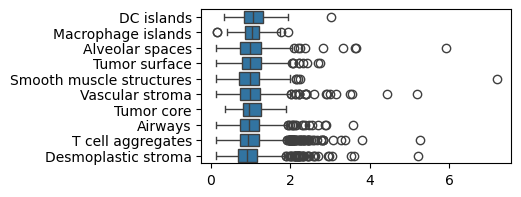

In [461]:
ddata = bdata.copy()
print(ddata.obs.celltypes.unique())
ddata.X = np.exp(np.asarray(ddata.X.todense()) - 1)
dataset_means = ddata[:, signature].X.mean(axis=0)
# dataset_means = np.median(ddata[:, signature].X, axis=0)
dataset_stds = ddata[:, signature].X.std(axis=0)
# fcs = (np.asarray(ddata[:, signature].X - dataset_means)) / dataset_stds
fcs = (np.asarray(ddata[:, signature].X / dataset_means)) #/ dataset_stds
ddata.obs.loc[:, f"{cytokine}_mean_fc_over_dataset_mean_div_std"] = np.nanmean(fcs, axis=1)

order = ddata.obs.groupby("niches_3D")[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1,1,figsize=(4, 2))
sns.boxplot(
    data = ddata.obs,
    y="niches_3D",
    x=f"{cytokine}_mean_fc_over_dataset_mean_div_std",
    order=order,
    ax=ax
)
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()

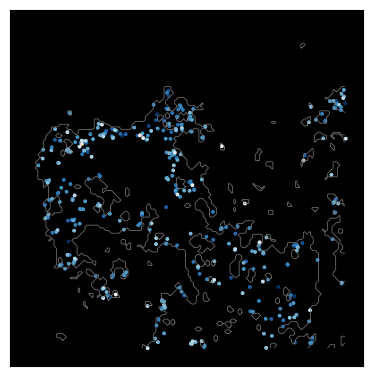

In [466]:
min_len = 6
linewidth = 0.5
contours_tumor, binsize, x_min, y_min = get_contour(
    cdata, 
    target_labels=["Tumor core", "Tumor surface"], 
    binsize=8
)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_facecolor("black")
plot_contour(contours_tumor, binsize, x_min, y_min, ax, min_len, linecolor="gray", linewidth=linewidth)
vmin = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].min()
vmax = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].max()#quantile(0.98)
center = (vmax-vmin) / 2

# _data = ddata[ddata.obs.niches_3D == "Tumor core"]
# _data = ddata[ddata.obs.niches_3D == "Desmoplastic stroma"]
_data = ddata[ddata.obs.niches_3D.isin(["Tumor surface"])]
idcs = _data.obs.sort_values(f"{cytokine}_mean_fc_over_dataset_mean_div_std").index
_data = _data[idcs]

sq.pl.spatial_scatter(
    #ddata[ddata.obs.niches_3D == "T cell aggregates"],
    _data,
    shape=None, 
    # color=f"{cytokine}_mean_fc_over_dataset_mean_div_std", 
    color=f"{cytokine}_mean_fc_over_dataset_mean_div_std",
    size=10, 
    ax=ax, 
    cmap=custom_cmap("RdBu_r", vmin=vmin, vmax=vmax, center=1),
    
    #vmin=vmin, vmax = ddata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].quantile(0.9),
)
plt.title(label=None)
plt.xlabel(None)
plt.ylabel(None)
plt.xlim(xlim)
plt.ylim(ylim)

fig.delaxes(fig.axes[-1])
if False:
    plt.savefig(
        f"./figures/spatial_scatter_{section}_{celltype_adata}_{celltype_signature}_{cytokine}_all.svg",
        bbox_inches="tight",
        pad_inches=0
    )
plt.show()

In [467]:
vmin

np.float32(-0.6324794)

In [468]:
vmax

np.float32(1.3187139)

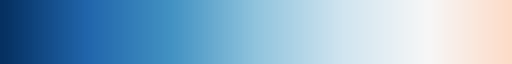

In [470]:
custom_cmap("RdBu_r", vmin=vmin, vmax=vmax, center=1)

In [ ]:
min_len = 6
linewidth = 0.5
contours_tumor, binsize, x_min, y_min = get_contour(
    cdata, 
    target_labels=["Tumor core", "Tumor surface"], 
    binsize=8
)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_facecolor("black")
plot_contour(contours_tumor, binsize, x_min, y_min, ax, min_len, linecolor="gray", linewidth=linewidth)
vmin = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].min()
vmax = bdata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].max()#quantile(0.98)
center = (vmax-vmin) / 2



sq.pl.spatial_scatter(
    ddata[ddata.obs.niches_3D == "T cell aggregates"],
    shape=None, 
    # color=f"{cytokine}_mean_fc_over_dataset_mean_div_std", 
    color=f"{cytokine}_mean_fc_over_dataset_mean_div_std",
    size=10, 
    ax=ax, 
    cmap=custom_cmap("Reds", vmin=vmin, vmax=vmax, center=center),
    vmin=vmin, vmax = ddata.obs[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].quantile(0.9),
)
plt.title(label=None)
plt.xlabel(None)
plt.ylabel(None)
plt.xlim(xlim)
plt.ylim(ylim)

fig.delaxes(fig.axes[-1])
if False:
    plt.savefig(
        f"./figures/spatial_scatter_{section}_{celltype_adata}_{celltype_signature}_{cytokine}_all.svg",
        bbox_inches="tight",
        pad_inches=0
    )
plt.show()

In [52]:
bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_expression"].mean()

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_93433/149375184.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_expression"].mean()


niches_3D
Airways                     0.561938
Alveolar spaces             0.564089
DC islands                  0.582959
Desmoplastic stroma         0.558557
Macrophage islands          0.630343
Smooth muscle structures    0.545019
T cell aggregates           0.553028
Tumor core                  0.712403
Tumor surface               0.677919
Vascular stroma             0.554401
Name: GM-CSF_mean_expression, dtype: float32

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_93433/3692174092.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_expression"].mean().sort_values(ascending=False).index


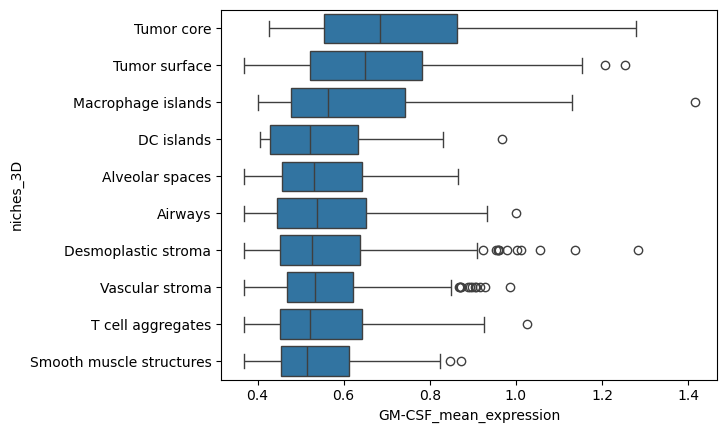

In [65]:
order = bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_expression"].mean().sort_values(ascending=False).index
sns.boxplot(
    data = bdata.obs,
    y="niches_3D",
    x=f"{cytokine}_mean_expression",
    order=order,
)
plt.show()

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_93433/1408752593.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].median().sort_values(ascending=False).index


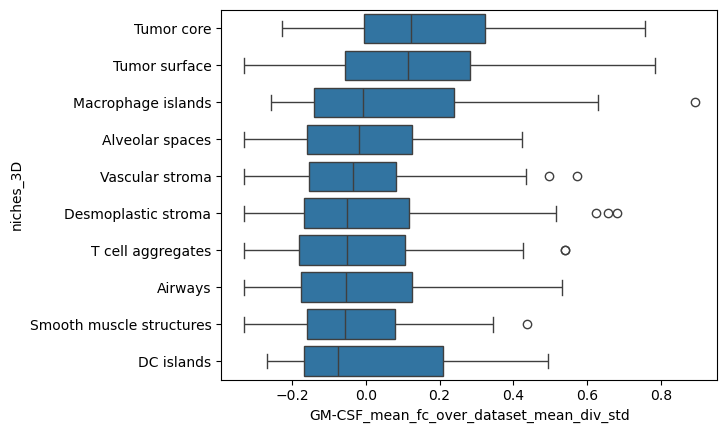

In [121]:
order = bdata.obs.groupby("niches_3D")[f"{cytokine}_mean_fc_over_dataset_mean_div_std"].median().sort_values(ascending=False).index
sns.boxplot(
    data = bdata.obs,
    y="niches_3D",
    x=f"{cytokine}_mean_fc_over_dataset_mean_div_std",
    order=order,
)
plt.show()

0.36787945 0.5235387 1.4149569


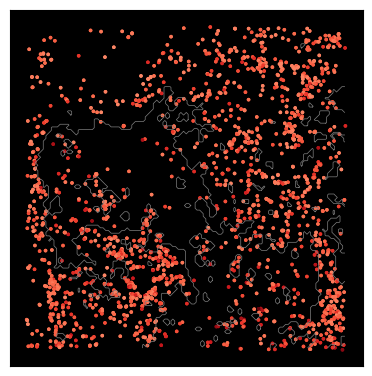

In [62]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_facecolor("black")
plot_contour(contours_tumor, binsize, x_min, y_min, ax, min_len, linecolor="gray", linewidth=linewidth)

vmin = bdata.obs[f"{cytokine}_mean_expression"].min()
vmax = bdata.obs[f"{cytokine}_mean_expression"].max()#quantile(0.98)
center = (vmax-vmin) / 2
print(vmin, center, vmax)
sq.pl.spatial_scatter(
    bdata, 
    shape=None, 
    # color=f"{cytokine}_mean_fc_over_dataset_mean_div_std", 
    color=f"{cytokine}_mean_expression",
    size=10, 
    ax=ax, 
    cmap=custom_cmap("Reds", vmin=vmin, vmax=vmax, center=center),
    #vmin=vmin, vmax=vmax,
)
plt.title(label=None)
plt.xlabel(None)
plt.ylabel(None)
plt.xlim(xlim)
plt.ylim(ylim)

fig.delaxes(fig.axes[-1])
if False:
    plt.savefig(
        f"./figures/spatial_scatter_{section}_{celltype_adata}_{celltype_signature}_{cytokine}_all.svg",
        bbox_inches="tight",
        pad_inches=0
    )
plt.show()